# Churn Drivers — Cox Proportional-Hazards Model

**Objective.** Estimate how much each customer attribute (channel, plan, discount) changes churn risk **while holding the others constant**,
test whether those effects are stable across tenure, and produce a retention curve and 24-month value for every customer profile.

**Why this follows Kaplan-Meier.** KM and log-rank (notebook 03) compare one variable at a time, so they can't separate overlapping effects
(for example, if discounts were concentrated in paid social). They also can't give a curve for a specific *combination* such as
"referral + annual + no discount." A regression model does both.

**Scope.** Within observed tenure (≤ 24 months). No projection beyond the data.

---

### Summary of findings

1. **All three attributes independently drive churn.** Holding the others constant: discount **+36%** churn risk, paid social **+20%** vs. search,
   referral **−26%**, annual plan **−33%** (all p < 0.001). Adjusted and one-at-a-time estimates are nearly identical, so the attributes
   don't overlap enough to distort each other.
2. **Attributes explain only part of churn** (concordance 0.60). Most of the variation in who churns comes from factors we don't observe.
3. **Effects are mostly stable across tenure.** Discount and referral pass the proportional-hazards test. Plan and paid social show mild
   fading after month 3 (p ≈ 0.03–0.06). Allowing for this (a stratified model) changes profile values by about $2 at most, so it isn't decision-relevant.
4. **The standard Cox survival curves overstate retention** on this monthly data (24-month value +4%). This comes from treating monthly data as continuous time.
   A **discrete-time proportional-hazards model** gives the same hazard ratios and matches the KM curves.
5. **Customer value ranges about 2× across profiles,** from about **$64** (paid social, monthly, discounted) to about **$133** (referral, no discount, either plan).
   CAC caps should be set by profile, not with one blended number.

In [1]:
import sys
sys.path.insert(0, "../src")

import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from lifelines import CoxPHFitter, KaplanMeierFitter
from lifelines.statistics import proportional_hazard_test

from retention import person_month
from ltv import ltv

HORIZON = 24
TENURES = range(HORIZON + 1)
MARGIN = {"monthly": 14.0, "annual": 11.0}

customers = pd.read_csv("../data/customers.csv")

# Model matrix: reference levels = search, monthly, no discount
X = pd.DataFrame({
    "T": customers.months_observed,
    "E": customers.churned,
    "paid_social": customers.channel.eq("paid_social").astype(int),
    "referral": customers.channel.eq("referral").astype(int),
    "annual": customers.plan.eq("annual").astype(int),
    "discount": customers.discount_at_signup,
})
FEATURES = ["paid_social", "referral", "annual", "discount"]
X.head()

,T,E,paid_social,referral,annual,discount
0,1,1,0,1,0,0
1,6,0,1,0,1,0
2,8,1,0,1,0,1
3,5,1,0,0,1,1
4,4,1,1,0,1,0


## 1. The model

Cox models each customer's monthly churn risk (hazard) as a **shared baseline curve** scaled up or down by their attributes:

$$h(t \mid x) = h_0(t) \times e^{\beta_1 x_1 + \beta_2 x_2 + \dots}$$

- $h_0(t)$ is the baseline risk by tenure for the reference customer (search, monthly, no discount). It's **left completely free**: Cox doesn't
  assume a shape, which is why it's called *semi-parametric*.
- $e^{\beta}$ is the **hazard ratio (HR)**: how many times riskier a customer with that attribute is, at every tenure. HR = 1.36 means 36% higher monthly churn risk.

**Assumptions to check:**

| Assumption | What it means here | If violated |
|---|---|---|
| **Proportional hazards** | Each attribute's HR is the same in month 1 and month 20 | One HR misstates the effect early or late |
| Multiplicative effects | Paid social + discount risk = 1.20 × 1.36 | Combinations mispriced (fix: add interactions) |
| Non-informative censoring | Same as KM | Biased estimates |
| All relevant drivers included | Only what's in the data is controlled for | Effects confounded, and unobserved differences between customers bias HRs toward 1 |

## 2. Hazard ratios

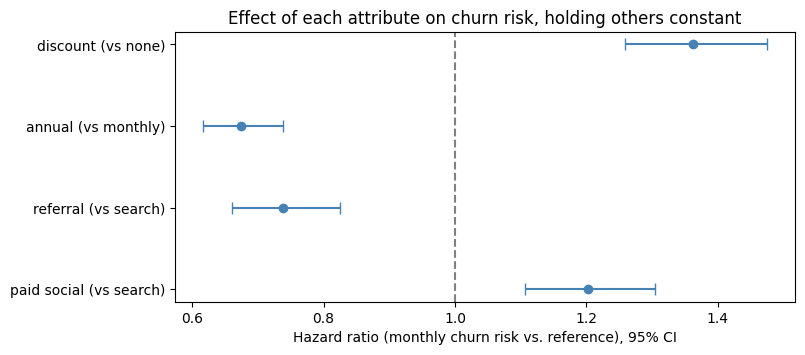

Concordance: 0.595


,HR (adjusted),HR (one at a time),CI low,CI high,p-value
covariate,,,,,
paid_social,1.202,1.201,1.107,1.305,0.0
referral,0.738,0.744,0.661,0.825,0.0
annual,0.675,0.678,0.617,0.739,0.0
discount,1.363,1.351,1.259,1.475,0.0


In [2]:
cox = CoxPHFitter().fit(X, "T", "E")

# One-at-a-time (unadjusted) HRs, for comparison
unadjusted = {}
for cols in [["paid_social", "referral"], ["annual"], ["discount"]]:
    m = CoxPHFitter().fit(X[["T", "E"] + cols], "T", "E")
    unadjusted.update(m.hazard_ratios_.to_dict())

hr = cox.summary[["exp(coef)", "exp(coef) lower 95%", "exp(coef) upper 95%", "p"]]
hr.columns = ["HR (adjusted)", "CI low", "CI high", "p-value"]
hr.insert(1, "HR (one at a time)", pd.Series(unadjusted))

fig, ax = plt.subplots(figsize=(8, 3.5))
y = np.arange(len(hr))
ax.errorbar(hr["HR (adjusted)"], y, xerr=[hr["HR (adjusted)"] - hr["CI low"], hr["CI high"] - hr["HR (adjusted)"]],
            fmt="o", capsize=4, color="steelblue")
ax.axvline(1, color="grey", ls="--")
ax.set_yticks(y, ["paid social (vs search)", "referral (vs search)", "annual (vs monthly)", "discount (vs none)"])
ax.set_xlabel("Hazard ratio (monthly churn risk vs. reference), 95% CI")
ax.set_title("Effect of each attribute on churn risk, holding others constant")
plt.show()

print(f"Concordance: {cox.concordance_index_:.3f}")
hr.round(3)

**Takeaway:** discount (+36%) and paid social (+20%) raise churn risk. Annual (−33%) and referral (−26%) lower it. Every interval excludes 1.
Adjusted HRs match the one-at-a-time HRs to within 0.01, so the effects are **separate**, not proxies for each other, and the segment views in
notebooks 02–03 weren't distorted by overlap.

**Concordance = 0.60** means that for a random pair of customers, the model correctly picks who churns first 60% of the time (0.5 = coin flip).
The attributes matter, but **most of the differences between customers are unobserved**. That fits the rising month-over-month retention seen
*within* every segment in notebook 02. It also means these attributes alone can't support confident predictions for individual customers. They're
useful for pricing and budget decisions at the segment level.

## 3. Are the effects stable across tenure? (proportional-hazards test)

Two complementary checks:
- **Schoenfeld residual test:** a formal test of whether each HR drifts with tenure.
- **Early vs. late HRs:** fit the model separately for months 1–3 and for months 4+ (among customers who survived 3 months).

,test statistic,p-value
annual,4.955,0.026
discount,0.291,0.590
paid_social,4.303,0.038
referral,1.519,0.218


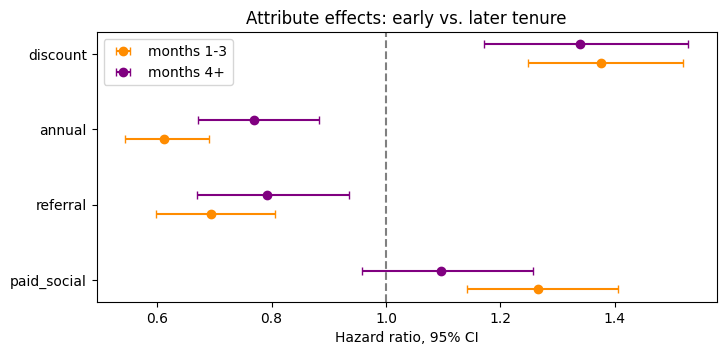

,HR months 1-3,HR months 4+
covariate,,
paid_social,1.266,1.097
referral,0.694,0.792
annual,0.613,0.769
discount,1.376,1.338


In [3]:
ph_test = proportional_hazard_test(cox, X, time_transform="rank").summary[["test_statistic", "p"]]
ph_test.columns = ["test statistic", "p-value"]

early = X.assign(E=np.where(X["T"] > 3, 0, X["E"]), T=X["T"].clip(upper=3))      # censor everyone at month 3
late = X[X["T"] > 3].assign(entry=3)                                                # survivors of month 3 only
cox_early = CoxPHFitter().fit(early, "T", "E")
cox_late = CoxPHFitter().fit(late, "T", "E", entry_col="entry")

piecewise = pd.DataFrame({"HR months 1-3": cox_early.hazard_ratios_, "HR months 4+": cox_late.hazard_ratios_})
display(ph_test.round(3))

fig, ax = plt.subplots(figsize=(8, 3.5))
for i, f in enumerate(FEATURES):
    for j, (m, color) in enumerate([(cox_early, "darkorange"), (cox_late, "purple")]):
        s = m.summary.loc[f]
        ax.errorbar(s["exp(coef)"], i + (j - 0.5) * 0.25,
                    xerr=[[s["exp(coef)"] - s["exp(coef) lower 95%"]], [s["exp(coef) upper 95%"] - s["exp(coef)"]]],
                    fmt="o", capsize=3, color=color, label=["months 1-3", "months 4+"][j] if i == 0 else None)
ax.axvline(1, color="grey", ls="--")
ax.set_yticks(range(len(FEATURES)), FEATURES)
ax.set_xlabel("Hazard ratio, 95% CI")
ax.set_title("Attribute effects: early vs. later tenure")
ax.legend()
plt.show()
piecewise.round(3)

**Takeaway:** discount's effect is the same early and late (1.38 vs. 1.34). The **annual** and **paid social** effects weaken after month 3 (annual 0.61 → 0.77,
paid social 1.27 → 1.10), with borderline test results (p ≈ 0.03–0.04). Every effect keeps its direction.

**Why would effects fade?** Two explanations, and the data can't separate them:
1. **Real fading:** e.g. an annual plan's lock-in matters most early on.
2. **Composition:** within each segment, the highest-risk customers leave first. Paid social survivors at month 6 are a filtered, stickier group,
   so they look more like everyone else. This is the same composition effect seen in notebook 02, now *inside* the model.

### Does the violation matter for decisions?
A **stratified Cox model** gives annual and monthly customers their own baseline curves, so it doesn't force a single plan HR. If profile values barely change, the simpler model is fine.

In [4]:
cox_strat = CoxPHFitter().fit(X, "T", "E", strata=["annual"])

profiles = pd.DataFrame([
    {"channel": ch, "plan": pl, "discount": d,
     "paid_social": int(ch == "paid_social"), "referral": int(ch == "referral"), "annual": int(pl == "annual")}
    for ch, pl, d in itertools.product(["paid_social", "search", "referral"], ["monthly", "annual"], [0, 1])
])
margins = profiles.plan.map(MARGIN).values

def profile_values(model):
    curves = model.predict_survival_function(profiles[FEATURES], times=TENURES)
    # select by label: stratified models return columns grouped by stratum, not in input order
    return np.array([ltv(curves[i].values, margins[i]) for i in profiles.index])

sensitivity = profiles[["channel", "plan", "discount"]].assign(
    cox=profile_values(cox), stratified=profile_values(cox_strat))
sensitivity["difference"] = sensitivity.stratified - sensitivity.cox
print(f"Largest absolute difference: ${sensitivity.difference.abs().max():.2f}")
sensitivity.round(1)

Largest absolute difference: $2.21


,channel,plan,discount,cox,stratified,difference
0,paid_social,monthly,0,92.1,92.8,0.7
1,paid_social,monthly,1,66.5,67.2,0.7
2,paid_social,annual,0,101.3,99.1,-2.2
3,paid_social,annual,1,78.3,76.5,-1.9
4,search,monthly,0,109.0,109.9,0.9
5,search,monthly,1,81.2,82.2,1.0
6,search,annual,0,115.1,113.0,-2.1
7,search,annual,1,91.8,89.9,-1.9
8,referral,monthly,0,137.9,138.8,0.9
9,referral,monthly,1,108.4,109.5,1.1


**Takeaway:** allowing plan its own baseline changes profile values by at most about $2. **The proportional-hazards violation is real but not
decision-relevant**, so we keep the simpler single model and note the caveat.

## 4. Calibration: do the model's curves match the observed data?

Hazard ratios are only half of the output. To value a profile we also need **absolute** retention curves. A basic check: average the
model's predicted curves over the customers in each segment and compare with that segment's KM curve.

In [5]:
def calibration(curve_fn):
    rows = []
    for name, mask in [("all", pd.Series(True, index=customers.index)),
                       ("paid_social", customers.channel.eq("paid_social")), ("search", customers.channel.eq("search")),
                       ("referral", customers.channel.eq("referral")), ("annual", customers.plan.eq("annual")),
                       ("monthly", customers.plan.eq("monthly")), ("discount", customers.discount_at_signup.eq(1))]:
        grp = customers[mask]
        km = KaplanMeierFitter().fit(grp.months_observed, grp.churned).survival_function_at_times(TENURES).values
        pred = curve_fn(mask)
        m = grp.monthly_margin.mean()
        rows.append({"segment": name, "KM M12": km[12], "model M12": pred[12],
                     "KM value": ltv(km, m), "model value": ltv(pred, m)})
    out = pd.DataFrame(rows).set_index("segment")
    out["value error"] = out["model value"] / out["KM value"] - 1
    return out

cox_curves = cox.predict_survival_function(X[FEATURES], times=TENURES)
cox_cal = calibration(lambda mask: cox_curves.loc[:, mask.values].mean(axis=1).values)
cox_cal.round(3)

,KM M12,model M12,KM value,model value,value error
segment,,,,,
all,0.249,0.274,97.811,101.764,0.040
paid_social,0.204,0.220,85.269,88.106,0.033
search,0.267,0.283,99.310,103.996,0.047
referral,0.328,0.391,125.037,130.959,0.047
annual,0.338,0.378,101.935,106.012,0.040
monthly,0.220,0.240,94.651,98.407,0.040
discount,0.181,0.201,80.328,83.230,0.036


**Takeaway:** the Cox curves sit **above** KM in every segment, overstating 24-month value by about 3–5%. The hazard ratios are fine; the problem
is in how the baseline curve is turned into survival probabilities.

In [6]:
km_all = KaplanMeierFitter().fit(customers.months_observed, customers.churned)
H0_month1 = cox.baseline_cumulative_hazard_.iloc[0, 0]
avg_cox_month1 = cox_curves.loc[1].mean()
print(f"Observed retention after month 1 (KM):        {km_all.survival_function_at_times(1).iloc[0]:.3f}")
print(f"Cox-predicted retention after month 1 (avg):  {avg_cox_month1:.3f}")
print(f"Churn events tied at month 1:                 {((customers.months_observed == 1) & (customers.churned == 1)).sum():,}")

Observed retention after month 1 (KM):        0.764
Cox-predicted retention after month 1 (avg):  0.792
Churn events tied at month 1:                 942


**Diagnosis:** Cox is a **continuous-time** model. It assumes churn events happen at distinct moments and converts cumulative hazard into survival
as $e^{-H}$. Our data is **monthly**: about 940 customers churn "at month 1" all at once, a 24% drop in a single step. When per-period risk is this large,
the continuous-time conversion overstates survival (79% vs. 76% after month 1), and the error compounds over 24 months.

**Fix: a discrete-time proportional-hazards model.** Expand the data to one row per customer per month at risk, and model *"did this customer churn
in this month?"* with a regression using a **complementary log-log** link. It has the same proportional-hazards structure (its exp(β) are hazard ratios)
but respects the monthly steps. Tenure is entered as bands (1, 2, 3, 4, 5, 6, 7–9, 10–12, 13–18, 19–24) to play the role of the baseline curve.

In [7]:
BANDS = [0, 1, 2, 3, 4, 5, 6, 9, 12, 18, 24]
band = lambda month: pd.cut(month, BANDS).astype(str)

pm = person_month(customers)
pm["tband"] = band(pm.month)
print(f"{len(pm):,} customer-months, {pm.event.sum():,} churn events")

dt = smf.glm(
    'event ~ C(tband) + C(channel, Treatment("search")) + C(plan, Treatment("monthly")) + discount_at_signup',
    data=pm, family=sm.families.Binomial(link=sm.families.links.CLogLog()),
).fit()

dt_hr = np.exp(pd.concat([dt.params, dt.conf_int()], axis=1)).iloc[-4:]
dt_hr.columns = ["HR (discrete-time)", "CI low", "CI high"]
dt_hr.index = FEATURES
dt_hr.insert(1, "HR (Cox)", cox.hazard_ratios_[FEATURES])
dt_hr.round(3)

21,762 customer-months, 2,809 churn events


,HR (discrete-time),HR (Cox),CI low,CI high
paid_social,1.203,1.202,1.107,1.306
referral,0.738,0.738,0.660,0.824
annual,0.674,0.675,0.616,0.738
discount,1.365,1.363,1.261,1.477


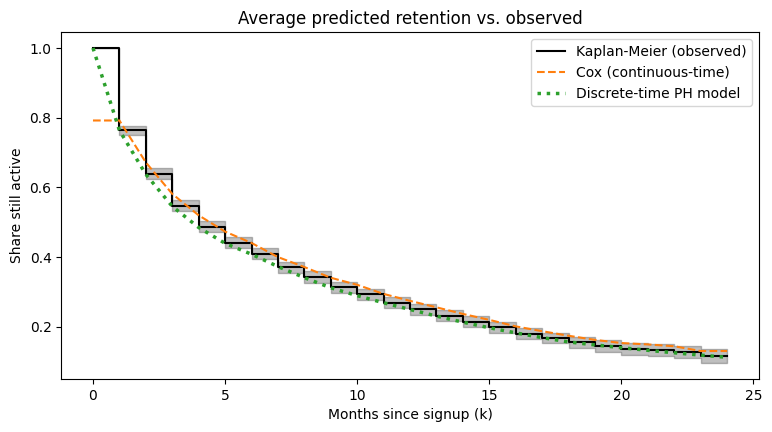

,Cox,Discrete-time
segment,,
all,0.040,-0.001
paid_social,0.033,-0.009
search,0.047,0.004
referral,0.047,0.008
annual,0.040,0.001
monthly,0.040,-0.003
discount,0.036,-0.005


In [8]:
def dt_survival(df):
    """Predicted retention curve S(0..24) for each row of df (columns: channel, plan, discount_at_signup)."""
    step = np.array([1 - dt.predict(df.assign(tband=band(pd.Series([k] * len(df), index=df.index)))).values
                     for k in range(1, HORIZON + 1)])
    return np.vstack([np.ones(len(df)), np.cumprod(step, axis=0)])

dt_curves = dt_survival(customers)
dt_cal = calibration(lambda mask: dt_curves[:, mask.values].mean(axis=1))

fig, ax = plt.subplots(figsize=(9, 4.5))
km_all.plot_survival_function(ax=ax, ci_show=True, color="black", label="Kaplan-Meier (observed)")
ax.plot(TENURES, cox_curves.mean(axis=1).values, ls="--", label="Cox (continuous-time)")
ax.plot(TENURES, dt_curves.mean(axis=1), ls=":", lw=2.5, label="Discrete-time PH model")
ax.set_title("Average predicted retention vs. observed")
ax.set_xlabel("Months since signup (k)")
ax.set_ylabel("Share still active")
ax.legend()
plt.show()

pd.concat({"Cox": cox_cal["value error"], "Discrete-time": dt_cal["value error"]}, axis=1).round(3)

**Takeaway:** the discrete-time model gives **the same hazard ratios** as Cox (to two decimals) and its curves match KM, with value errors around
±1% or less in every segment compared with +3–5% for Cox. **Use Cox for effect sizes; use the discrete-time version whenever you need absolute retention or dollar values from monthly data.**

## 5. 24-month value by customer profile

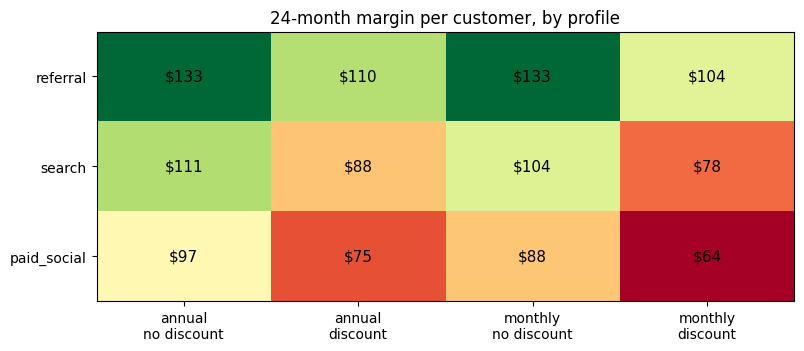

,channel,plan,discount_at_signup,customers,M3,M12,monthly_margin,value_24m
0,referral,annual,0,131,0.749,0.504,11.0,132.867
1,referral,monthly,0,405,0.651,0.362,14.0,132.627
2,search,annual,0,252,0.675,0.395,11.0,110.859
3,referral,annual,1,57,0.673,0.393,11.0,110.361
4,search,monthly,0,717,0.559,0.252,14.0,104.321
5,referral,monthly,1,167,0.556,0.250,14.0,103.714
6,paid_social,annual,0,315,0.624,0.327,11.0,97.193
7,paid_social,monthly,0,966,0.496,0.191,14.0,88.188
8,search,annual,1,99,0.585,0.282,11.0,87.925
9,search,monthly,1,320,0.452,0.153,14.0,77.894


In [9]:
profile_df = profiles.rename(columns={"discount": "discount_at_signup"})[["channel", "plan", "discount_at_signup"]]
profile_curves = dt_survival(profile_df)
n_customers = customers.groupby(["channel", "plan", "discount_at_signup"]).size()

values = profile_df.assign(
    customers=[n_customers.get(tuple(r), 0) for r in profile_df.itertuples(index=False)],
    M3=profile_curves[3], M12=profile_curves[12],
    monthly_margin=margins,
    value_24m=[ltv(profile_curves[:, i], margins[i]) for i in range(len(profile_df))],
).sort_values("value_24m", ascending=False)

pivot = values.pivot_table(index="channel", columns=["plan", "discount_at_signup"], values="value_24m").loc[["referral", "search", "paid_social"]]
fig, ax = plt.subplots(figsize=(9, 3.5))
im = ax.imshow(pivot.values, cmap="RdYlGn", aspect="auto")
ax.set_xticks(range(pivot.shape[1]), [f"{p}\n{'discount' if d else 'no discount'}" for p, d in pivot.columns])
ax.set_yticks(range(pivot.shape[0]), pivot.index)
for i in range(pivot.shape[0]):
    for j in range(pivot.shape[1]):
        ax.text(j, i, f"${pivot.values[i, j]:.0f}", ha="center", va="center", fontsize=11)
ax.set_title("24-month margin per customer, by profile")
plt.show()

values.round(3).reset_index(drop=True)

**Takeaway:** value roughly doubles from the weakest profile to the strongest. Each attribute's contribution is visible in the grid:
- **Discount** costs about $22–29 per customer in every profile, a consistent and large lever.
- **Channel:** referral is worth roughly $35–45 more than paid social for the same plan and discount, the largest gap in the grid.
- **Plan:** annual's better retention more than offsets its lower margin for paid social and search (+$7–11), but adds little for referral customers (+$0–7), who already retain well.

**Decision use:** set CAC caps per channel using that channel's actual plan and discount mix, and require a discount to lift conversion enough to
cover about $22–29 of lost value per customer. Small profiles (e.g. referral + annual + discount, n = 57) rely more on the model than on their own data.

## 6. Limitations

- **Observational, not causal.** HRs describe who churns more, after adjusting for the other attributes. They don't say what would happen if we changed
  discount policy. Discounts may *attract* price-sensitive customers rather than *cause* churn. Testing that requires an experiment.
- **Unobserved differences between customers dominate** (concordance 0.60). Unmeasured differences pull HRs toward 1 and likely explain part of the fading effects.
- **No extrapolation.** Both models' baselines are estimated only where data exists (≤ 24 months). They can't project beyond it, and need long history
  to estimate the later tenure bands.
- **Mild non-proportionality** for plan and paid social. Shown above not to change values materially, but it should be re-checked if the mix changes.

## 7. Next steps

**Parametric survival models (Weibull, sBG):** fit an explicit curve *shape* so retention can be **projected beyond observed tenure** and from
**short histories**. Then backtest: fit on only the first ~6 months of data and check how well each model recovers the 12–24 month retention observed here.